In [1]:
import os
import numpy as np
import torch

# set up device-agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"device: {device}")



device: cpu


In [2]:
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 13.3 MB/s  0:00:00


# Preprocessing Pipeline



In [3]:
"""
Preprocessing pipeline:
PDB structures --> fixed-size distance matrices for training a UNET diffusion model on
protein contact maps

"""
import os
import numpy as np
import torch
from Bio.PDB import PDBList, PDBParser
from Bio.PDB.Polypeptide import is_aa
import warnings

warnings.filterwarnings("ignore") # Bio.PDB is noisy about minor structure issue

# Add more IDs here when scaling up
# starting small and diverse (different fold classes) so can sanity check results
PDB_IDS = [
    "1UBQ",  # ubiquitin - small, mixed alpha/beta
    "1LYZ",  # lysozyme - alpha-helical
    "1CRN",  # crambin - small, mixed
    "2GB1",  # protein G B1 domain - beta sheet + helix
    "1BPI",  # BPTI - small, mostly beta
    "1MBN",  # myoglobin - all alpha helical
    "1PGA",  # protein G
    "1SHG",  # SH3 domain - all beta
    "1VII",  # villin headpiece - small alpha
    "2CI2",  # chymotrypsin inhibitor 2
    # RCSB advanced search -> allows filter by length/resolution: https://www.rcsb.org/search/advanced
]

TARGET_SIZE = 64 # fixed matrix size the UNET will train on
MAX_DIST_ANGSTROM = 40  # distances beyond this get clipped
# why 40? 40 is large and distances this far means residues are not interacting much

PAD_VALUE = -2.0        # sentinel for padded regions (mask these out in loss)
# -2 so that after normalizing dist_matrix, some normalised values can have -1.0
# if use -1 or 1 or 0, PAD_VALUE can coincide w the normalised values, skewing results
# as PAD_VALUE should be ignored
DOWNLOAD_DIR = "./pdb_raw"
OUTPUT_PATH = "./contact_maps.pt"


def get_ca_coordinates(structure):
    """
    Extract alpha carbon for all standard amino acids residues.
    Alpha carbon is like the standard one point per residue for course-grained structure rep.
    This means we can get exactly one (x, y, z) coordinate per residue

    returns L residues, 3 coordinates -> input to compute_distance_matrix
    """
    coords = []
    model = structure[0]
    # most x-ray structrues have only 1 model, but NMR can have multiple so [0] means get first one
    for chain in model: # model can have multiple chains
        for residue in chain:

            # for is_aa -> check if its canonical aa, skips water, ligands ions etc. which are
            # mixed into PDB files
            # "CA" in residue -> check if this residue only has 1 resolved alpha carbon
            # in disordered regions some atoms are missing/unresolved in crystal structures
            # this skips residues without a resolved CA
            if is_aa(residue, standard=True) and "CA" in residue:
                coords.append(residue["CA"].get_coord())
                # pulls the actual xyz coordinate of the Ca atom and appends it to a running list
        break # only take the first chain (limitation)
    return np.array(coords, dtype=np.float32) # returns shape of L, 3

def compute_distance_matrix(ca_coords):
    """
    Pairwise Euclidean matrix between all ca atoms
    uses vectorisation so loops are not used to speed things up computationally
    doing all the L^2 simultaneously
    """
    print(f"Ca_coords's shape: {ca_coords.shape}") # e.g. 2CI2: 65, 3
    diff = ca_coords[:,None,:] - ca_coords[None,:,:] # basically leads to [L, L, 3]
    # diff [i, j] is the displacement between both residues i and j

    return np.sqrt((diff**2).sum(-1)) # squares each of three components then sums along the last axis
    # sum(0) means summing across residue i, sum(1) means summing across residues j
    # shape: [L, L] # is a symmetric matrix
    # returned matrix will look like, with shape = (L, L)
    #    ┌─────────────────┐
    #    │ DISTANCE MATRIX │
    #    │                 │
    #    │ 0  d12 d13 d14  │
    #    │ d21 0  d23 d24  │
    #    │ d31 d32 0  d34  │
    #    │ d41 d42 d43 0   │
    #    └─────────────────┘

def crop_or_pad(dist_matrix, pad_value=PAD_VALUE, target_size=TARGET_SIZE):
    """
    Random continuous crop if too long, pad with sentinel if too short
    Limitation: cropping means model does not see full contact pattern but local windows
    """
    L = dist_matrix.shape[0]
    print(f"L:{L}")
    if L >= target_size:
        start = np.random.randint(0, L-target_size+1)
        dist_matrix = dist_matrix[start:start+target_size, start:start+target_size]
        return dist_matrix
    else:
        # this step will just fill the matrix w/ pad_value till it reaches targetsize X targetsize
        padded = np.full((target_size, target_size), pad_value, dtype=np.float32)
        # print(f"Padded: {padded.shape}")
        # makes sure the matrix still has a corner that contains the shorter protein's L
        padded[:L, :L]= dist_matrix
        print(f"Padded's shape: {padded.shape}")
        return padded # -> returns target_size, target_size # (128, 128)

def process_pdb_id(pdb_id, parser, pdbl):
    """
    Download, parse and convert one PDB entry into a fixed-size, normalized distance matrix.
    Returns None if anything goes wrong so 1 bad structure doesnt kill the whole batch.
    """
    try:
        pdb_path = pdbl.retrieve_pdb_file(pdb_id, pdir=DOWNLOAD_DIR, file_format="pdb")
        structure = parser.get_structure(pdb_id, pdb_path)
        ca_coords = get_ca_coordinates(structure)

        if len(ca_coords) <= 10:
            print(f"[skip] {pdb_id}: too few residues ({len(ca_coords)})")
            return None
        dist_matrix = compute_distance_matrix(ca_coords)
        dist_matrix = np.clip(dist_matrix, 0, MAX_DIST_ANGSTROM)

        # scaling to between -1 and 1 to match the range diffusion models typically expect
        # normalization convention in stable diffusion, data distribution centred at 0

        # normalise dist_matrix first before padding
        dist_matrix = (dist_matrix/MAX_DIST_ANGSTROM) *2 -1
        print(f"Dist_matrix shape: {dist_matrix.shape}") # e.g. 2CI2: (65, 65)

        fixed = crop_or_pad(dist_matrix)
        return fixed # shape: (targetsize, targetsize)

    except Exception as e:
        print(f"  [error] {pdb_id}: {e}")
        return None

def main():
    os.makedirs(DOWNLOAD_DIR, exist_ok=True)
    parser = PDBParser(QUIET=True)
    pdbl = PDBList()

    processed = []
    for pdb_id in PDB_IDS:
        print(f"Processing {pdb_id}...")
        result = process_pdb_id(pdb_id, parser, pdbl) # shape: targetsize, targetsize
        if result is not None:
            processed.append(result)

    if not processed:
        print("No structures processed successfully - check internet connection/PDB IDs")
        return

    dataset = torch.tensor(np.stack(processed), dtype=torch.float32).unsqueeze(1)
    # unsqueezing(1) adds a new dimension at the second position
    # shape= [N, 1, target size, target size] N is currently 10

    torch.save(dataset, OUTPUT_PATH)
    print(f"\nSaved {dataset.shape[0]} contact maps to {OUTPUT_PATH}")
    print(f"Tensor shape: {dataset.shape}")
    print(f"Tensor: {dataset}")
    print(f"Value range: [{dataset.min():.2f}, {dataset.max():.2f}] "
          f"({PAD_VALUE} = padding sentinel)")


if __name__=="__main__":
    main()



Processing 1UBQ...
Ca_coords's shape: (76, 3)
Dist_matrix shape: (76, 76)
L:76
Processing 1LYZ...
Ca_coords's shape: (129, 3)
Dist_matrix shape: (129, 129)
L:129
Processing 1CRN...
Ca_coords's shape: (46, 3)
Dist_matrix shape: (46, 46)
L:46
Padded's shape: (64, 64)
Processing 2GB1...
Ca_coords's shape: (56, 3)
Dist_matrix shape: (56, 56)
L:56
Padded's shape: (64, 64)
Processing 1BPI...
Ca_coords's shape: (58, 3)
Dist_matrix shape: (58, 58)
L:58
Padded's shape: (64, 64)
Processing 1MBN...
Ca_coords's shape: (153, 3)
Dist_matrix shape: (153, 153)
L:153
Processing 1PGA...
Ca_coords's shape: (56, 3)
Dist_matrix shape: (56, 56)
L:56
Padded's shape: (64, 64)
Processing 1SHG...
Ca_coords's shape: (57, 3)
Dist_matrix shape: (57, 57)
L:57
Padded's shape: (64, 64)
Processing 1VII...
Ca_coords's shape: (36, 3)
Dist_matrix shape: (36, 36)
L:36
Padded's shape: (64, 64)
Processing 2CI2...
Ca_coords's shape: (65, 3)
Dist_matrix shape: (65, 65)
L:65

Saved 10 contact maps to ./contact_maps.pt
Tensor s

In [4]:
tensor_path="contact_maps.pt"

contact_maps_data = torch.load(tensor_path)

print(f"contact maps data: {contact_maps_data}")

contact maps data: tensor([[[[-1.0000, -0.8091, -0.7213,  ..., -0.6467, -0.6722, -0.5838],
          [-0.8091, -1.0000, -0.8113,  ..., -0.4995, -0.5061, -0.4655],
          [-0.7213, -0.8113, -1.0000,  ..., -0.4656, -0.4184, -0.3362],
          ...,
          [-0.6467, -0.4995, -0.4656,  ..., -1.0000, -0.8094, -0.6749],
          [-0.6722, -0.5061, -0.4184,  ..., -0.8094, -1.0000, -0.8085],
          [-0.5838, -0.4655, -0.3362,  ..., -0.6749, -0.8085, -1.0000]]],


        [[[-1.0000, -0.8194, -0.7344,  ...,  0.3280,  0.1869,  0.0856],
          [-0.8194, -1.0000, -0.8177,  ...,  0.4510,  0.3094,  0.1933],
          [-0.7344, -0.8177, -1.0000,  ...,  0.4732,  0.3176,  0.2143],
          ...,
          [ 0.3280,  0.4510,  0.4732,  ..., -1.0000, -0.8160, -0.7131],
          [ 0.1869,  0.3094,  0.3176,  ..., -0.8160, -1.0000, -0.8091],
          [ 0.0856,  0.1933,  0.2143,  ..., -0.7131, -0.8091, -1.0000]]],


        [[[-1.0000, -0.8103, -0.6648,  ..., -2.0000, -2.0000, -2.0000],
       

# Visualising the distance matrix

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


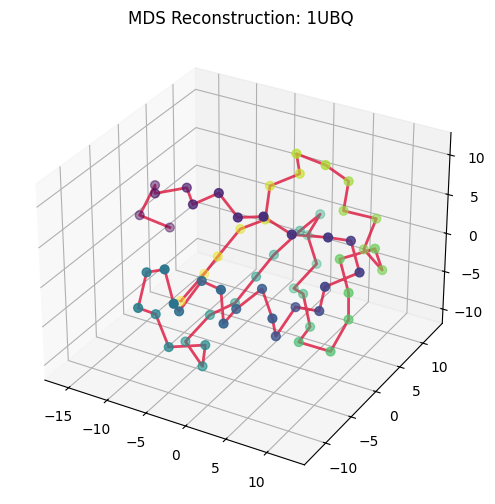

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


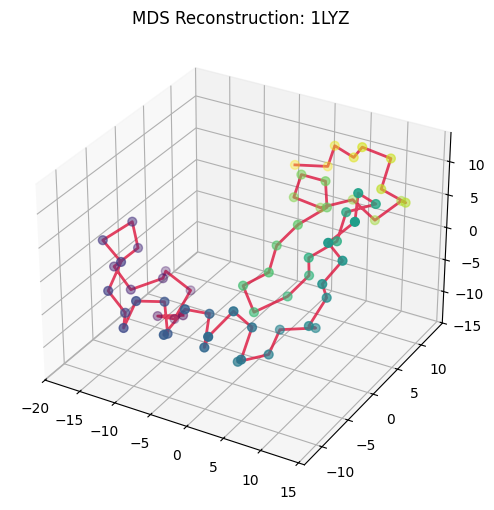

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


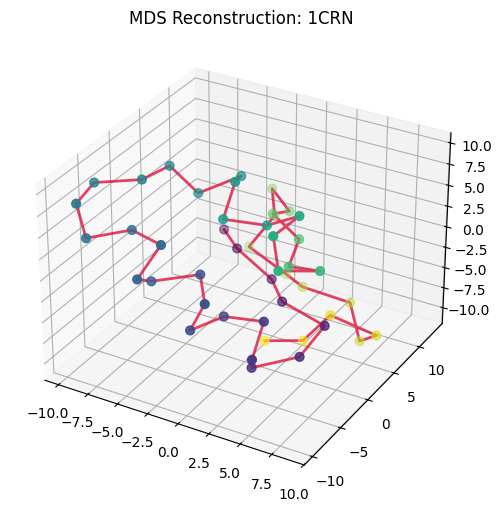

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


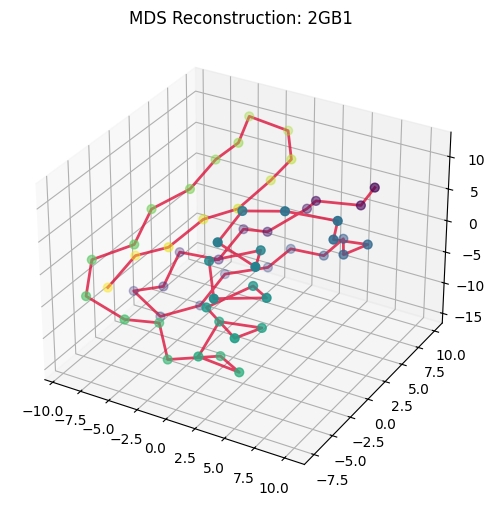

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


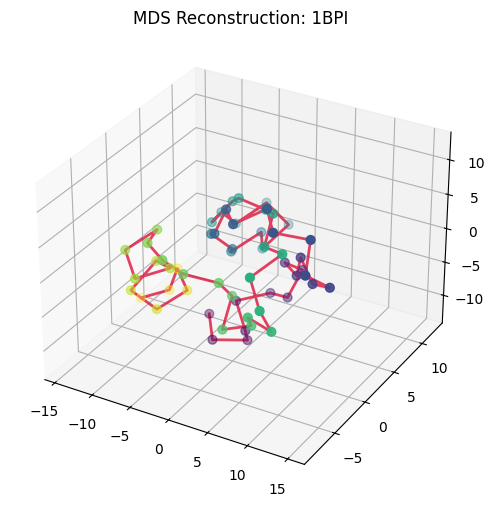

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


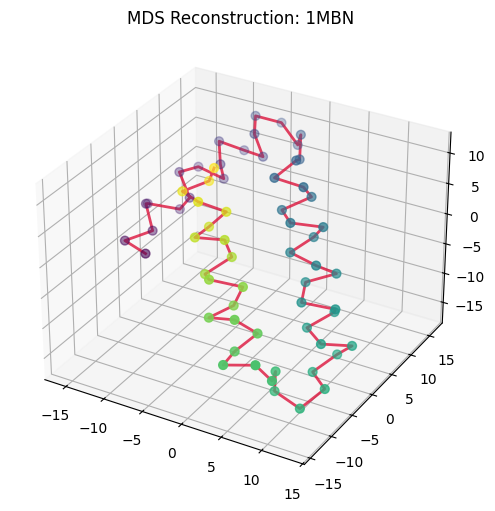

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


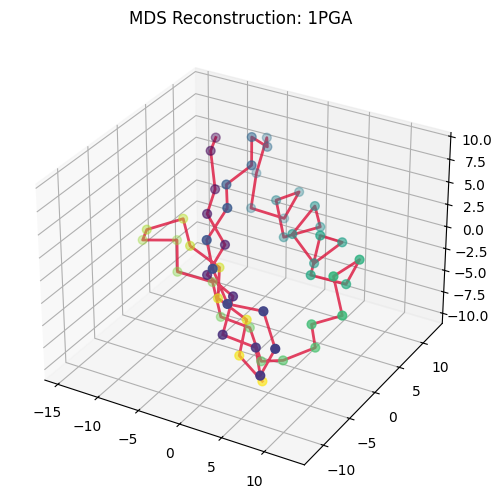

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


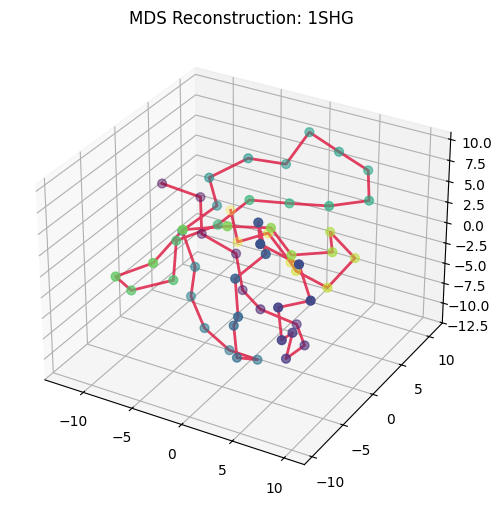

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


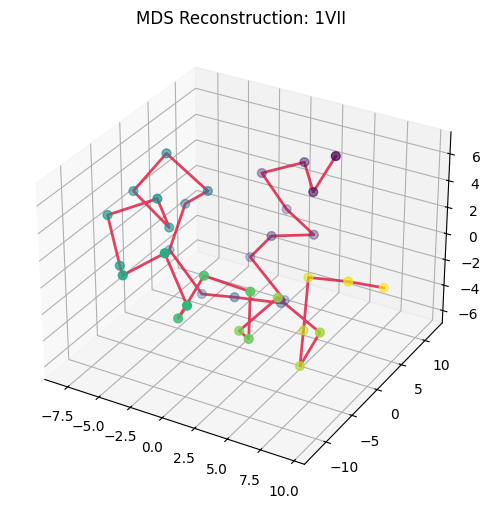

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


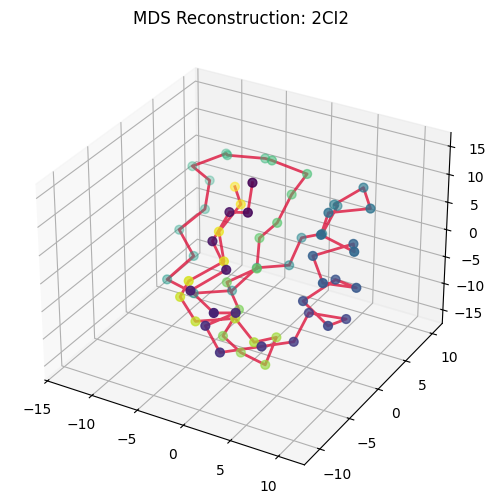

In [6]:
# visualising the distance matrix
import matplotlib.pyplot as plt
import numpy as np
from sklearn.manifold import MDS

# 1. Un-normalise and remove padding before running MDS
for i, map_tensor in enumerate(contact_maps_data):
  # enumerate interates over the 1st dimension
  # N, 1, 64, 64 -> 1, 64, 64
    print(f"Contact maps data: {contact_maps_data.shape}") # Contact maps data: torch.Size([10, 1, 64, 64])
    # 10 = number of maps
    # 1 = channels
    # height = 64
    # width = 64

    map_np = map_tensor.squeeze().cpu().numpy()
    print(f"map_np: {map_np.shape}") # (64, 64)

    # Identify valid residues (exclude padded sentinel values)
    valid_mask = map_np[:, 0] != PAD_VALUE # taking only the first column
    valid_map = map_np[valid_mask][:, valid_mask]

    # Invert the [-1, 1] normalization back to original Angstrom scale
    dist_matrix_angstrom = ((valid_map + 1) / 2) * MAX_DIST_ANGSTROM

    # Force symmetry
    # For every pair of residues, take the average of the predicted A→B and B→A distances,
    # so that we have one consistent distance for the pair
    dist_matrix_sym = (dist_matrix_angstrom + dist_matrix_angstrom.T) / 2

    # 2. Run Metric MDS
    mds = MDS(
        n_components=3,
        dissimilarity="precomputed",
        random_state=42,
        n_init=10,
        max_iter=500,
    )
    generated_coords = mds.fit_transform(dist_matrix_sym)

    # 3. Plot 3D C-alpha Backbone Trace
    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(projection="3d")

    # Trace line connecting sequential residues
    ax.plot(
        generated_coords[:, 0],
        generated_coords[:, 1],
        generated_coords[:, 2],
        color="crimson",
        linewidth=2,
        alpha=0.8,
        label="Cα Trace",
    )

    # Scatter points for C-alpha atoms
    ax.scatter(
        generated_coords[:, 0],
        generated_coords[:, 1],
        generated_coords[:, 2],
        c=np.arange(len(generated_coords)), # giving each generated coordinate a color in viridis
        cmap="viridis",
        s=40,
    )

    ax.set_title(f"MDS Reconstruction: {PDB_IDS[i]}")
    plt.show()

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


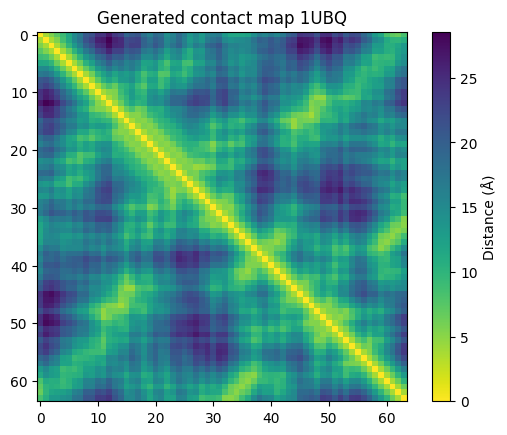

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


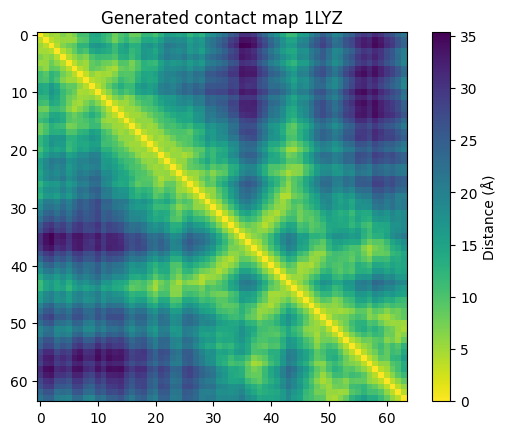

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


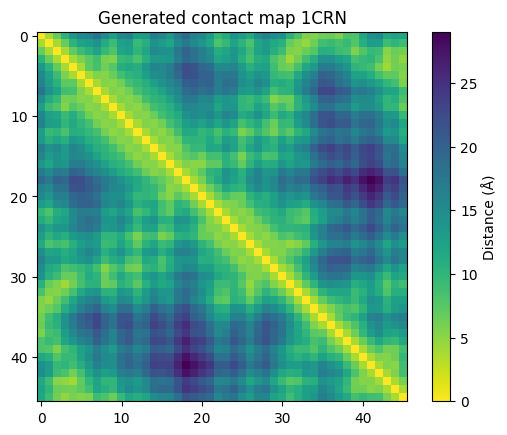

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


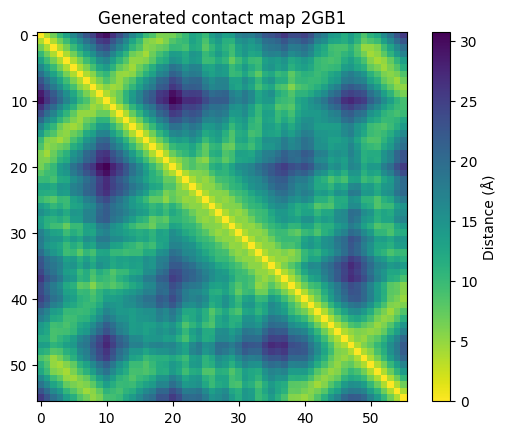

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


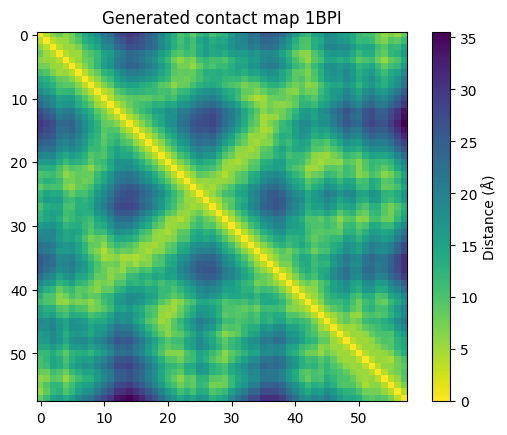

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


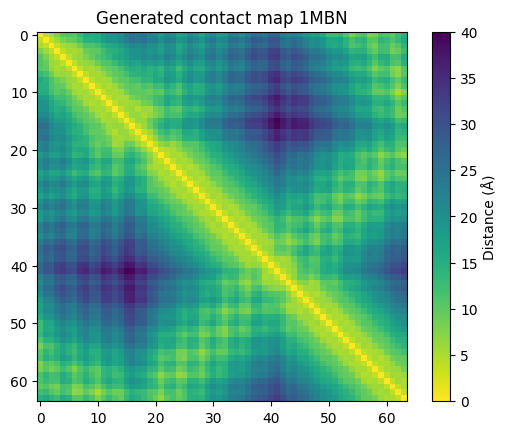

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


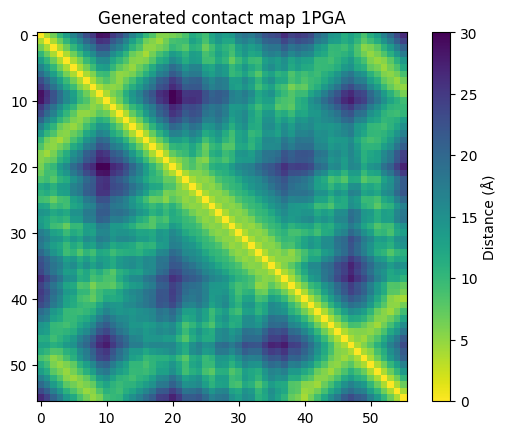

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


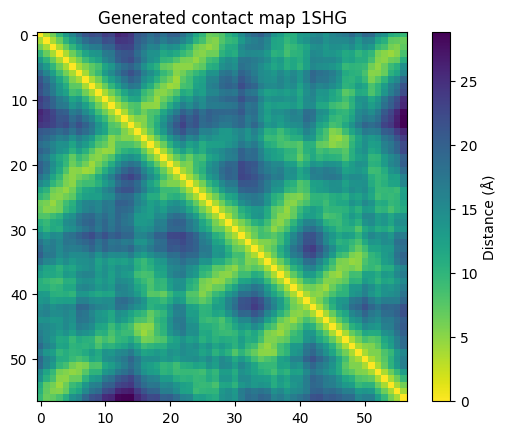

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


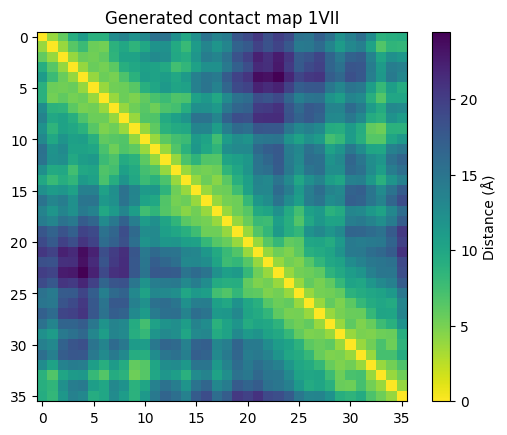

Contact maps data: torch.Size([10, 1, 64, 64])
map_np: (64, 64)


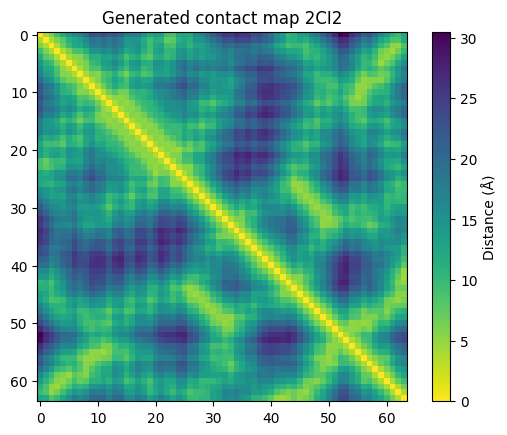

In [8]:
import matplotlib.pyplot as plt
# generating heatmap to visualize distance matrix generated

for i, map_tensor in enumerate(contact_maps_data):
  # enumerate interates over the 1st dimension
  # N, 1, 64, 64 -> 1, 64, 64
    print(f"Contact maps data: {contact_maps_data.shape}") # Contact maps data: torch.Size([10, 1, 64, 64])
    # 10 = number of maps
    # 1 = channels
    # height = 64
    # width = 64

    map_np = map_tensor.squeeze().cpu().numpy()
    print(f"map_np: {map_np.shape}") # (64, 64)

    # Identify valid residues (exclude padded sentinel values)
    valid_mask = map_np[:, 0] != PAD_VALUE # taking only the first column
    valid_map = map_np[valid_mask][:, valid_mask]

    # Invert the [-1, 1] normalization back to original Angstrom scale
    dist_matrix_angstrom = ((valid_map + 1) / 2) * MAX_DIST_ANGSTROM
    """
    A real fold shows a bright diagonal stripe (adjacent residues are always close)
    plus off-diagonal patterns -> thick parallel bands near the diagonal for helices,
    or isolated bright blocks away from the diagonal for beta sheets/long-range contacts
    """
    # dist_matrix_angstrom = result.squeeze()
    # valid_mask = map_np[:,0] != PAD_VALUE
    # valid_map = map_np[valid_mask][:, valid_mask]
    # dist_matrix_angstrom = ((valid_map+1)/2) * MAX_DIST_ANGSTROM

    plt.imshow(dist_matrix_angstrom, cmap="viridis_r")  # reversed so close = bright
    plt.colorbar(label="Distance (Å)")
    plt.title(f"Generated contact map {PDB_IDS[i]}")
    plt.show()

In [ ]:
# creating a custom dataset
from torch.utils.data import Dataset, DataLoader

class ContactMapDataset(Dataset):
    """
    wraps the prepocessed contact-map tensor for use with Dataloader.
    """
    def __init__(self, data):
        self.data= data
    def __len__(self):
        """ returns the number of samples"""
        return self.data.shape[0]
    def __getitem__(self, index):
      """returns a particular sample in x, y"""
      return self.data[index]

In [ ]:
import os

n = int(0.8*len(contact_maps_data))
train_data = contact_maps_data[:n]
test_data = contact_maps_data[n:]
print(f"test data shape: {test_data.shape}") # 2,1,128,128 -> correct

test data shape: torch.Size([2, 1, 64, 64])


In [ ]:
import os

train_dataset= ContactMapDataset(train_data) # ContactMapDataset takes in tensor
test_dataset = ContactMapDataset(test_data)
train_dataloader = DataLoader(train_dataset,
                              shuffle=True,
                              num_workers=0,
                              pin_memory=False)
test_dataloader = DataLoader(test_dataset,
                             shuffle=False,
                             num_workers=0,
                             pin_memory=False)

print(f"Length of train_data: {len(train_data)}")
x= next(iter(train_dataloader))
print(f"Length of x: {len(x)}")
print(f"Shape of x: {x.shape}") # didn't specify batch_size, so pytorch defaults to 1
print(f"length of train_dataloader: {len(train_dataloader)}")

Length of train_data: 8
Length of x: 1
Shape of x: torch.Size([1, 1, 64, 64])
length of train_dataloader: 8


In [ ]:
import torch
from torch import nn
from torch.nn import functional as F
import math

class SelfAttention(nn.Module):
    def __init__(self, n_heads, d_embed, in_proj_bias=True, out_proj_bias=True):
        super().__init__()
        # This combines the Wq, Wk and Wv matrices into one matrix
        # projection of input
        self.in_proj = nn.Linear(d_embed, 3 * d_embed, bias=in_proj_bias)
        # packing three separate matrices (Wq, Wk, Wv) into one linear layer so you can do one matmul instead of three


        # This one represents the Wo matrix
        # projection of output # Wo = dmodel by dmodel
        self.out_proj = nn.Linear(d_embed, d_embed, bias=out_proj_bias)
        self.n_heads = n_heads
        self.d_head = d_embed // n_heads

    def forward(self, x, causal_mask=False):
        # x: # (Batch_Size, Seq_Len, Dim)

        # (Batch_Size, Seq_Len, Dim)
        # extract the shape
        input_shape = x.shape

        # (Batch_Size, Seq_Len, Dim)
        # extract the sizes, seq length and embeddings
        batch_size, sequence_length, d_embed = input_shape

        # (Batch_Size, Seq_Len, H, Dim / H)
        # intermediate shape
        interim_shape = (batch_size, sequence_length, self.n_heads, self.d_head)

        # (Batch_Size, Seq_Len, Dim) -> (Batch_Size, Seq_Len, Dim * 3) -> 3 tensor of shape (Batch_Size, Seq_Len, Dim)
        q, k, v = self.in_proj(x).chunk(3, dim=-1)

        # (Batch_Size, Seq_Len, Dim) -> (Batch_Size, Seq_Len, H, Dim / H) -> (Batch_Size, H, Seq_Len, Dim / H)
        q = q.view(interim_shape).transpose(1, 2)
        k = k.view(interim_shape).transpose(1, 2)
        v = v.view(interim_shape).transpose(1, 2)

        # (Batch_Size, H, Seq_Len, Dim / H) @ (Batch_Size, H, Dim / H, Seq_Len) -> (Batch_Size, H, Seq_Len, Seq_Len)
        weight = q @ k.transpose(-1, -2)

        if causal_mask:
            # Mask where the upper triangle (above the principal diagonal) is 1
            mask = torch.ones_like(weight, dtype=torch.bool).triu(1)
            # Fill the upper triangle with -inf
            weight.masked_fill_(mask, -torch.inf)

        # Divide by d_k (Dim / H).
        # (Batch_Size, H, Seq_Len, Seq_Len) -> (Batch_Size, H, Seq_Len, Seq_Len)
        weight /= math.sqrt(self.d_head)

        # (Batch_Size, H, Seq_Len, Seq_Len) -> (Batch_Size, H, Seq_Len, Seq_Len)
        weight = F.softmax(weight, dim=-1)

        # (Batch_Size, H, Seq_Len, Seq_Len) @ (Batch_Size, H, Seq_Len, Dim / H) -> (Batch_Size, H, Seq_Len, Dim / H)
        output = weight @ v

        # (Batch_Size, H, Seq_Len, Dim / H) -> (Batch_Size, Seq_Len, H, Dim / H)
        output = output.transpose(1, 2)

        # (Batch_Size, Seq_Len, H, Dim / H) -> (Batch_Size, Seq_Len, Dim)
        output = output.reshape(input_shape)  # want to remove the head dimension

        # (Batch_Size, Seq_Len, Dim) -> (Batch_Size, Seq_Len, Dim)
        output = self.out_proj(output)

        # (Batch_Size, Seq_Len, Dim)
        return output

class CrossAttention(nn.Module):
    def __init__(self, n_heads, d_embed, d_cross, in_proj_bias=True, out_proj_bias=True):
        super().__init__()
        self.q_proj   = nn.Linear(d_embed, d_embed, bias=in_proj_bias)
        self.k_proj   = nn.Linear(d_cross, d_embed, bias=in_proj_bias)
        self.v_proj   = nn.Linear(d_cross, d_embed, bias=in_proj_bias)
        self.out_proj = nn.Linear(d_embed, d_embed, bias=out_proj_bias)
        self.n_heads = n_heads
        self.d_head = d_embed // n_heads

    def forward(self, x, y):
        # x (latent): # (Batch_Size, Seq_Len_Q, Dim_Q)
        # y (context): # (Batch_Size, Seq_Len_KV, Dim_KV) = (Batch_Size, 77, 768)

        input_shape = x.shape
        batch_size, sequence_length, d_embed = input_shape
        # Divide each embedding of Q into multiple heads such that d_heads * n_heads = Dim_Q
        interim_shape = (batch_size, -1, self.n_heads, self.d_head)

        # (Batch_Size, Seq_Len_Q, Dim_Q) -> (Batch_Size, Seq_Len_Q, Dim_Q)
        q = self.q_proj(x)
        # (Batch_Size, Seq_Len_KV, Dim_KV) -> (Batch_Size, Seq_Len_KV, Dim_Q)
        k = self.k_proj(y)
        # (Batch_Size, Seq_Len_KV, Dim_KV) -> (Batch_Size, Seq_Len_KV, Dim_Q)
        v = self.v_proj(y)

        # (Batch_Size, Seq_Len_Q, Dim_Q) -> (Batch_Size, Seq_Len_Q, H, Dim_Q / H) -> (Batch_Size, H, Seq_Len_Q, Dim_Q / H)
        q = q.view(interim_shape).transpose(1, 2)
        # (Batch_Size, Seq_Len_KV, Dim_Q) -> (Batch_Size, Seq_Len_KV, H, Dim_Q / H) -> (Batch_Size, H, Seq_Len_KV, Dim_Q / H)
        k = k.view(interim_shape).transpose(1, 2)
        # (Batch_Size, Seq_Len_KV, Dim_Q) -> (Batch_Size, Seq_Len_KV, H, Dim_Q / H) -> (Batch_Size, H, Seq_Len_KV, Dim_Q / H)
        v = v.view(interim_shape).transpose(1, 2)

        # (Batch_Size, H, Seq_Len_Q, Dim_Q / H) @ (Batch_Size, H, Dim_Q / H, Seq_Len_KV) -> (Batch_Size, H, Seq_Len_Q, Seq_Len_KV)
        weight = q @ k.transpose(-1, -2)

        # (Batch_Size, H, Seq_Len_Q, Seq_Len_KV)
        weight /= math.sqrt(self.d_head)

        # (Batch_Size, H, Seq_Len_Q, Seq_Len_KV)
        weight = F.softmax(weight, dim=-1)

        # (Batch_Size, H, Seq_Len_Q, Seq_Len_KV) @ (Batch_Size, H, Seq_Len_KV, Dim_Q / H) -> (Batch_Size, H, Seq_Len_Q, Dim_Q / H)
        output = weight @ v # don't need causal masking

        # (Batch_Size, H, Seq_Len_Q, Dim_Q / H) -> (Batch_Size, Seq_Len_Q, H, Dim_Q / H)
        output = output.transpose(1, 2).contiguous()

        # (Batch_Size, Seq_Len_Q, H, Dim_Q / H) -> (Batch_Size, Seq_Len_Q, Dim_Q)
        output = output.view(input_shape)

        # (Batch_Size, Seq_Len_Q, Dim_Q) -> (Batch_Size, Seq_Len_Q, Dim_Q)
        output = self.out_proj(output)

        # (Batch_Size, Seq_Len_Q, Dim_Q)
        return output

In [ ]:
# HYPERPARAMS

n_time = 64
n_embd = 64
n_head = 4

In [ ]:
import torch
from torch import nn
from torch.nn import functional as F
# from attention import SelfAttention, CrossAttention

class TimeEmbedding(nn.Module):

    def __init__(self, n_embd):
        super().__init__()
        self.linear_1 = nn.Linear(n_embd, 4 * n_embd)
        self.linear_2 = nn.Linear(4 * n_embd, 4 * n_embd)

    def forward(self, x):
        # x: (1, 64)

        # (1, 64) -> (1, 256)
        x = self.linear_1(x)

        # (1, 256) -> (1, 256) # adds non-linearity
        x = F.silu(x)

        # (1, 256) -> (1, 256)
        x = self.linear_2(x)

        # (1, 256)
        return x

class UNET_ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, n_time=256):
        # n_time is 256 because TimeEmbedding(64) -> outputs 256 in linear_2
        super().__init__()
        self.groupnorm_feature = nn.GroupNorm(8, in_channels)
        self.conv_feature = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.linear_time = nn.Linear(n_time, out_channels)

        self.groupnorm_merged = nn.GroupNorm(8, out_channels)
        self.conv_merged = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1)

        if in_channels == out_channels:
            self.residual_layer = nn.Identity()
        else:
            self.residual_layer = nn.Conv2d(in_channels, out_channels, kernel_size=1, padding=0)

    def forward(self, feature, time): # need to combine 3 info tgt: time, prompt & latent
        # needs to relate everything tgt
        # feature: (Batch_Size, In_Channels, Height, Width)
        # time: (1, 256)

        residue = feature

        # (Batch_Size, In_Channels, Height, Width) -> (Batch_Size, In_Channels, Height, Width)
        feature = self.groupnorm_feature(feature)

        # (Batch_Size, In_Channels, Height, Width) -> (Batch_Size, In_Channels, Height, Width)
        feature = F.silu(feature)

        # (Batch_Size, In_Channels, Height, Width) -> (Batch_Size, Out_Channels, Height, Width)
        feature = self.conv_feature(feature)

        # (1, 256) -> (1, 256)
        time = F.silu(time)

        # (1, 256) -> (1, Out_Channels)
        time = self.linear_time(time)

        # Add width and height dimension to time.
        # (Batch_Size, Out_Channels, Height, Width) + (1, Out_Channels, 1, 1) -> (Batch_Size, Out_Channels, Height, Width)
        merged = feature + time.unsqueeze(-1).unsqueeze(-1) # time embeddings doesnt have batch and channels dimensions
        # so its added with unsqueeze

        # (Batch_Size, Out_Channels, Height, Width) -> (Batch_Size, Out_Channels, Height, Width)
        merged = self.groupnorm_merged(merged)

        # (Batch_Size, Out_Channels, Height, Width) -> (Batch_Size, Out_Channels, Height, Width)
        merged = F.silu(merged)

        # (Batch_Size, Out_Channels, Height, Width) -> (Batch_Size, Out_Channels, Height, Width)
        merged = self.conv_merged(merged)

        # (Batch_Size, Out_Channels, Height, Width) + (Batch_Size, Out_Channels, Height, Width) -> (Batch_Size, Out_Channels, Height, Width)
        return merged + self.residual_layer(residue)

class UNET_AttentionBlock(nn.Module):
    def __init__(self, n_head: int, n_embd: int, d_context=768):
        super().__init__()
        channels = n_head * n_embd

        self.groupnorm = nn.GroupNorm(8, channels, eps=1e-6)
        self.conv_input = nn.Conv2d(channels, channels, kernel_size=1, padding=0)

        self.layernorm_1 = nn.LayerNorm(channels)
        self.attention_1 = SelfAttention(n_head, channels, in_proj_bias=False)
        self.layernorm_2 = nn.LayerNorm(channels)
        self.attention_2 = CrossAttention(n_head, channels, d_context, in_proj_bias=False)
        self.layernorm_3 = nn.LayerNorm(channels)
        self.linear_geglu_1  = nn.Linear(channels, 4 * channels * 2)
        self.linear_geglu_2 = nn.Linear(4 * channels, channels)

        self.conv_output = nn.Conv2d(channels, channels, kernel_size=1, padding=0)

    def forward(self, x, context):
        # x: (Batch_Size, Features, Height, Width) x is our latent
        # context: (Batch_Size, Seq_Len, Dim) context is the prompt

        residue_long = x

        # (Batch_Size, Features, Height, Width) -> (Batch_Size, Features, Height, Width)
        x = self.groupnorm(x)

        # (Batch_Size, Features, Height, Width) -> (Batch_Size, Features, Height, Width)
        x = self.conv_input(x)

        n, c, h, w = x.shape

        # (Batch_Size, Features, Height, Width) -> (Batch_Size, Features, Height * Width)
        x = x.view((n, c, h * w))

        # (Batch_Size, Features, Height * Width) -> (Batch_Size, Height * Width, Features)
        x = x.transpose(-1, -2) # to apply cross attention
        # first self attention then cross attention

        # Normalization + Self-Attention with skip connection

        # (Batch_Size, Height * Width, Features)
        residue_short = x

        # (Batch_Size, Height * Width, Features) -> (Batch_Size, Height * Width, Features)
        x = self.layernorm_1(x)

        # (Batch_Size, Height * Width, Features) -> (Batch_Size, Height * Width, Features)
        x = self.attention_1(x)

        # (Batch_Size, Height * Width, Features) + (Batch_Size, Height * Width, Features) -> (Batch_Size, Height * Width, Features)
        x += residue_short

        # (Batch_Size, Height * Width, Features)
        residue_short = x

        # Normalization + Cross-Attention with skip connection

        # (Batch_Size, Height * Width, Features) -> (Batch_Size, Height * Width, Features)
        x = self.layernorm_2(x)

        # (Batch_Size, Height * Width, Features) -> (Batch_Size, Height * Width, Features)
        x = self.attention_2(x, context)

        # (Batch_Size, Height * Width, Features) + (Batch_Size, Height * Width, Features) -> (Batch_Size, Height * Width, Features)
        x += residue_short

        # (Batch_Size, Height * Width, Features)
        residue_short = x

        # Normalization + FFN with GeGLU and skip connection

        # (Batch_Size, Height * Width, Features) -> (Batch_Size, Height * Width, Features)
        x = self.layernorm_3(x)

        # GeGLU as implemented in the original code: https://github.com/CompVis/stable-diffusion/blob/21f890f9da3cfbeaba8e2ac3c425ee9e998d5229/ldm/modules/attention.py#L37C10-L37C10
        # (Batch_Size, Height * Width, Features) -> two tensors of shape (Batch_Size, Height * Width, Features * 4)
        x, gate = self.linear_geglu_1(x).chunk(2, dim=-1)

        # Element-wise product: (Batch_Size, Height * Width, Features * 4) * (Batch_Size, Height * Width, Features * 4) -> (Batch_Size, Height * Width, Features * 4)
        x = x * F.gelu(gate)

        # (Batch_Size, Height * Width, Features * 4) -> (Batch_Size, Height * Width, Features)
        x = self.linear_geglu_2(x)

        # (Batch_Size, Height * Width, Features) + (Batch_Size, Height * Width, Features) -> (Batch_Size, Height * Width, Features)
        x += residue_short

        # (Batch_Size, Height * Width, Features) -> (Batch_Size, Features, Height * Width)
        x = x.transpose(-1, -2)

        # (Batch_Size, Features, Height * Width) -> (Batch_Size, Features, Height, Width)
        x = x.view((n, c, h, w))

        # Final skip connection between initial input and output of the block
        # (Batch_Size, Features, Height, Width) + (Batch_Size, Features, Height, Width) -> (Batch_Size, Features, Height, Width)
        return self.conv_output(x) + residue_long

class Upsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, kernel_size=3, padding=1)

    def forward(self, x):
        # (Batch_Size, Features, Height, Width) -> (Batch_Size, Features, Height * 2, Width * 2)
        x = F.interpolate(x, scale_factor=2, mode='nearest')
        return self.conv(x)

class SwitchSequential(nn.Sequential):
    def forward(self, x, context, time):
        for layer in self:
            if isinstance(layer, UNET_AttentionBlock): # cross attention between latents and the prompt
                x = layer(x, context)
            elif isinstance(layer, UNET_ResidualBlock):
                x = layer(x, time)
            else:
                x = layer(x)
        return x

class UNET(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoders = nn.ModuleList([ # changing to 1 to match contact maps
            # (Batch_Size, 1, Height / 8, Width / 8) -> (Batch_Size, 64, Height / 8, Width / 8)

            SwitchSequential(nn.Conv2d(1, 64, kernel_size=3, padding=1)),

            # (Batch_Size, 64, Height / 8, Width / 8) -> # (Batch_Size, 64, Height / 8, Width / 8) -> (Batch_Size, 64, Height / 8, Width / 8)
            SwitchSequential(UNET_ResidualBlock(64, 64), UNET_AttentionBlock(4, 16)), # 4*16 = 64 as channels = n_head * n_embd
                                        # 4, 16 matches output from ResBlock


            # (Batch_Size, 64, Height / 8, Width / 8) -> # (Batch_Size, 64, Height / 8, Width / 8) -> (Batch_Size, 64, Height / 8, Width / 8)
            SwitchSequential(UNET_ResidualBlock(64, 64), UNET_AttentionBlock(4, 16)),

            # (Batch_Size, 64, Height / 8, Width / 8) -> (Batch_Size, 64, Height / 16, Width / 16)
            SwitchSequential(nn.Conv2d(64, 64, kernel_size=3, stride=2, padding=1)),

            # (Batch_Size, 64, Height / 16, Width / 16) -> (Batch_Size, 128, Height / 16, Width / 16) -> (Batch_Size, 128, Height / 16, Width / 16)
            SwitchSequential(UNET_ResidualBlock(64, 128), UNET_AttentionBlock(4, 32)),

            # (Batch_Size, 128, Height / 16, Width / 16) -> (Batch_Size, 128, Height / 16, Width / 16) -> (Batch_Size, 128, Height / 16, Width / 16)
            SwitchSequential(UNET_ResidualBlock(128, 128), UNET_AttentionBlock(4, 32)),
            # in attention block, 4 is num_head, 32 is embedding size
            # how to transform the output of residual block into a sequence to run attention on it

            # (Batch_Size, 128, Height / 16, Width / 16) -> (Batch_Size, 128, Height / 32, Width / 32)
            SwitchSequential(nn.Conv2d(128, 128, kernel_size=3, stride=2, padding=1)),

            # (Batch_Size, 128, Height / 32, Width / 32) -> (Batch_Size, 256, Height / 32, Width / 32) -> (Batch_Size, 256, Height / 32, Width / 32)
            SwitchSequential(UNET_ResidualBlock(128, 256), UNET_AttentionBlock(4, 64)),

            # (Batch_Size, 256, Height / 32, Width / 32) -> (Batch_Size, 256, Height / 32, Width / 32) -> (Batch_Size, 256, Height / 32, Width / 32)
            SwitchSequential(UNET_ResidualBlock(256, 256), UNET_AttentionBlock(4, 64)),

            # (Batch_Size, 256, Height / 32, Width / 32) -> (Batch_Size, 256, Height / 64, Width / 64)
            SwitchSequential(nn.Conv2d(256, 256, kernel_size=3, stride=2, padding=1)),

            # (Batch_Size, 256, Height / 64, Width / 64) -> (Batch_Size, 256, Height / 64, Width / 64)
            SwitchSequential(UNET_ResidualBlock(256, 256)),

            # (Batch_Size, 256, Height / 64, Width / 64) -> (Batch_Size, 256, Height / 64, Width / 64)
            SwitchSequential(UNET_ResidualBlock(256, 256)),
        ])

        self.bottleneck = SwitchSequential(
            # (Batch_Size, 256, Height / 64, Width / 64) -> (Batch_Size, 256, Height / 64, Width / 64)
            UNET_ResidualBlock(256, 256),

            # (Batch_Size, 256, Height / 64, Width / 64) -> (Batch_Size, 256, Height / 64, Width / 64)
            UNET_AttentionBlock(4, 64),

            # (Batch_Size, 256, Height / 64, Width / 64) -> (Batch_Size, 256, Height / 64, Width / 64)
            UNET_ResidualBlock(256, 256),
        )

        self.decoders = nn.ModuleList([ # opposite to encoder, will reduce num_features but increase image size
            # (Batch_Size, 512, Height / 64, Width / 64) -> (Batch_Size, 256, Height / 64, Width / 64)
            # bottleneck outputs 256
            # double the amount here because of skip connections at each layer


            SwitchSequential(UNET_ResidualBlock(512, 256)),

            # (Batch_Size, 512, Height / 64, Width / 64) -> (Batch_Size, 256, Height / 64, Width / 64)
            SwitchSequential(UNET_ResidualBlock(512, 256)),

            # (Batch_Size, 512, Height / 64, Width / 64) -> (Batch_Size, 256, Height / 64, Width / 64) -> (Batch_Size, 256, Height / 32, Width / 32)
            SwitchSequential(UNET_ResidualBlock(512, 256), Upsample(256)),

            # (Batch_Size, 512, Height / 32, Width / 32) -> (Batch_Size, 256, Height / 32, Width / 32) -> (Batch_Size, 256, Height / 32, Width / 32)
            SwitchSequential(UNET_ResidualBlock(512, 256), UNET_AttentionBlock(4, 64)),

            # (Batch_Size, 512, Height / 32, Width / 32) -> (Batch_Size, 256, Height / 32, Width / 32) -> (Batch_Size, 256, Height / 32, Width / 32)
            SwitchSequential(UNET_ResidualBlock(512, 256), UNET_AttentionBlock(4, 64)),

            # (Batch_Size, 384, Height / 32, Width / 32) -> (Batch_Size, 256, Height / 32, Width / 32) -> (Batch_Size, 256, Height / 32, Width / 32) -> (Batch_Size, 1280, Height / 16, Width / 16)
            SwitchSequential(UNET_ResidualBlock(384, 256), UNET_AttentionBlock(4, 64), Upsample(256)),

            # contains the skip connections so 256 -> 128
            # concat encoder's & decoder's features
            # 256 + 128 -> 384
            # (Batch_Size, 284, Height / 16, Width / 16) -> (Batch_Size, 128, Height / 16, Width / 16) -> (Batch_Size, 128, Height / 16, Width / 16)
            SwitchSequential(UNET_ResidualBlock(384, 128), UNET_AttentionBlock(4, 32)),

            # (Batch_Size, 256, Height / 16, Width / 16) -> (Batch_Size, 128, Height / 16, Width / 16) -> (Batch_Size, 128, Height / 16, Width / 16)
            SwitchSequential(UNET_ResidualBlock(256, 128), UNET_AttentionBlock(4, 32)),

            # (Batch_Size, 192, Height / 16, Width / 16) -> (Batch_Size, 128, Height / 16, Width / 16) -> (Batch_Size, 128, Height / 16, Width / 16) -> (Batch_Size, 640, Height / 8, Width / 8)
            SwitchSequential(UNET_ResidualBlock(192, 128), UNET_AttentionBlock(4, 32), Upsample(128)), #upsample increases size of image

            # (Batch_Size, 192, Height / 8, Width / 8) -> (Batch_Size, 64, Height / 8, Width / 8) -> (Batch_Size, 64, Height / 8, Width / 8)
            SwitchSequential(UNET_ResidualBlock(192, 64), UNET_AttentionBlock(4, 16)),

            # (Batch_Size, 128, Height / 8, Width / 8) -> (Batch_Size, 64, Height / 8, Width / 8) -> (Batch_Size, 64, Height / 8, Width / 8)
            SwitchSequential(UNET_ResidualBlock(128, 64), UNET_AttentionBlock(4, 16)),

            # (Batch_Size, 128, Height / 8, Width / 8) -> (Batch_Size, 64, Height / 8, Width / 8) -> (Batch_Size, 64, Height / 8, Width / 8)
            SwitchSequential(UNET_ResidualBlock(128, 64), UNET_AttentionBlock(4, 16)), # shape of output of the unet
        ])

    def forward(self, x, context, time):
        # x: (Batch_Size, 1, Height / 8, Width / 8)
        # context: (Batch_Size, Seq_Len, Dim)
        # time: (1, 256) 64 * 4

        skip_connections = []
        for layers in self.encoders:
            x = layers(x, context, time)
            skip_connections.append(x) # x is the L residues (64 x 64)
            # WHAT this does:
                # Coordinates from PDB
                #     ↓
                # Conv2D
                #     ↓
                # feature representation
                #     ↓
                # Residual block
                #     ↓
                # refined feature representation
                #     ↓
                # Attention
                #     ↓
                # feature representation with spatial/contextual relationships incorporated

        x = self.bottleneck(x, context, time)

        for layers in self.decoders:
            # Since we always concat with the skip connection of the encoder, the number of features increases before being sent to the decoder's layer
            x = torch.cat((x, skip_connections.pop()), dim=1)
            x = layers(x, context, time)

        return x


class UNET_OutputLayer(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.groupnorm = nn.GroupNorm(8, in_channels)
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)

    def forward(self, x): # x is the L residues
        # x: (Batch_Size, 64, Height / 8, Width / 8)

        # (Batch_Size, 64, Height / 8, Width / 8) -> (Batch_Size, 64, Height / 8, Width / 8)
        x = self.groupnorm(x)

        # (Batch_Size, 64, Height / 8, Width / 8) -> (Batch_Size, 64, Height / 8, Width / 8)
        x = F.silu(x)

        # (Batch_Size, 64, Height / 8, Width / 8) -> (Batch_Size, 1, Height / 8, Width / 8)
        x = self.conv(x)

        # (Batch_Size, 1, Height / 8, Width / 8)
        return x

class Diffusion(nn.Module):
    def __init__(self):
        super().__init__()
        self.time_embedding = TimeEmbedding(64)
        self.unet = UNET()
        self.final = UNET_OutputLayer(64, 1) # the outputlayer -> we needto go back to the same number of features
        # the decoder will not build the final number of features we need which is 1, so we need an
        # output layer to go back to the original size of the features
        # output dimension must match input dimension bcz input to unet
        # -> predict noise-> sched removes it -> again

    def forward(self, latent, context, time):
        # latent: (Batch_Size, 4, Height / 8, Width / 8) # 1 is the output of the prep contact maps code
        # context: (Batch_Size, Seq_Len, Dim) # our prompt # Dim is 768 -> torch.zeros
        # time: (1, 64)

        # (1, 64) -> (1, 256) # also uses wave functions e.g. sine and cosine
        time = self.time_embedding(time) # time step at which it is noisified

        # (Batch, 1, Height / 8, Width / 8) -> (Batch, 64, Height / 8, Width / 8)
        output = self.unet(latent, context, time)


        # (Batch, 64, Height / 8, Width / 8) -> (Batch, 1, Height / 8, Width / 8)
        output = self.final(output)

        # (Batch, 1, Height / 8, Width / 8)
        return output

In [ ]:
import torch
import numpy as np

generator = torch.Generator()
generator.manual_seed(0)

class DDPMSampler:

    def __init__(self, generator: torch.Generator, num_training_steps=1000, beta_start: float = 0.00085, beta_end: float = 0.0120):
        # gievn an image that has less noise, how to get a noisier image acc to a gaussian distribution
        # the noise that we add varies acc to a variance schedule: beta1, beta2, betat
        # these beta values are a series of numbers that indicates the variance of the noise that we add with each of these steps
        # Params "beta_start" and "beta_end" taken from: https://github.com/CompVis/stable-diffusion/blob/21f890f9da3cfbeaba8e2ac3c425ee9e998d5229/configs/stable-diffusion/v1-inference.yaml#L5C8-L5C8
        # For the naming conventions, refer to the DDPM paper (https://arxiv.org/pdf/2006.11239.pdf)
        self.betas = torch.linspace(beta_start ** 0.5, beta_end ** 0.5, num_training_steps, dtype=torch.float32) ** 2
        # the scaled linear scheduler # makes scheduler a linear schedule

        self.alphas = 1.0 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, dim=0) # [alpha_0, alpha_0 * alpha_1, alpha_0 * alpha_1 * alpha_2] cumulative product
        self.one = torch.tensor(1.0)

        self.generator = generator

        self.num_train_timesteps = num_training_steps
        self.timesteps = torch.from_numpy(np.arange(0, num_training_steps)[::-1].copy()) # reversed this bcz 1000 to 0

    def set_inference_timesteps(self, num_inference_steps=50):
        self.num_inference_steps = num_inference_steps
        # will be from 999, 998,997... 0
        # but we dont want 1000 numbers, we want 50, so theyre spaced out # 999, 979, 959, ... 0 = 50 steps

        step_ratio = self.num_train_timesteps // self.num_inference_steps
        timesteps = (np.arange(0, num_inference_steps) * step_ratio).round()[::-1].copy().astype(np.int64)
        self.timesteps = torch.from_numpy(timesteps)

    def _get_previous_timestep(self, timestep: int) -> int:
        prev_t = timestep - self.num_train_timesteps // self.num_inference_steps
        return prev_t # given number 999, it'll return 979

    def _get_variance(self, timestep: int) -> torch.Tensor:
        prev_t = self._get_previous_timestep(timestep)

        alpha_prod_t = self.alphas_cumprod[timestep]
        alpha_prod_t_prev = self.alphas_cumprod[prev_t] if prev_t >= 0 else self.one
        current_beta_t = 1 - alpha_prod_t / alpha_prod_t_prev

        # For t > 0, compute predicted variance βt (see formula (6) and (7) from https://arxiv.org/pdf/2006.11239.pdf)
        # and sample from it to get previous sample
        # x_{t-1} ~ N(pred_prev_sample, variance) == add variance to pred_sample
        # computed using formula 7 of the ddpm paper
        variance = (1 - alpha_prod_t_prev) / (1 - alpha_prod_t) * current_beta_t

        # we always take the log of variance, so clamp it to ensure it's not 0
        variance = torch.clamp(variance, min=1e-20)

        return variance

    def set_strength(self, strength=1):
        """
            Set how much noise to add to the input image.
            More noise (strength ~ 1) means that the output will be further from the input image.
            Less noise (strength ~ 0) means that the output will be closer to the input image.
        """
        # start_step is the number of noise levels to skip
        start_step = self.num_inference_steps - int(self.num_inference_steps * strength)
        self.timesteps = self.timesteps[start_step:]
        self.start_step = start_step

    # for generation
# two ways of equivalence - going from more noisy to less noisy from 2006.11369 paper
    # 1. algorithm 2 sampling eqn 4
    # 2. equation no.7 (what we are using)
    # they have diff parameteriization, so diff formuale
    # calc prev sample given the current one
    def step(self, timestep: int, latents: torch.Tensor, model_output: torch.Tensor):
        t = timestep # can skip some timesteps, tell it the timesteps at which it shud remove the noise
        # latent is x_t

        # given what I currently have, infer what the less-noisy thing probably was
        prev_t = self._get_previous_timestep(t) # given this timestep, caculate the previous one

        # 1. compute alphas, betas # from huggingface diffusers
        alpha_prod_t = self.alphas_cumprod[t]
        alpha_prod_t_prev = self.alphas_cumprod[prev_t] if prev_t >= 0 else self.one
        beta_prod_t = 1 - alpha_prod_t
        beta_prod_t_prev = 1 - alpha_prod_t_prev
        current_alpha_t = alpha_prod_t / alpha_prod_t_prev
        current_beta_t = 1 - current_alpha_t

        # need to get x_0 from equation 7, hence, use equation 15 to calculate x_0
        # 2. compute predicted original sample from predicted noise also called
        # "predicted x_0" of formula (15) from https://arxiv.org/pdf/2006.11239.pdf
        pred_original_sample = (latents - beta_prod_t ** (0.5) * model_output) / alpha_prod_t ** (0.5)
        pred_original_sample = pred_original_sample.clamp(-1, 1)
        # unet predicts the noise, i.e. the model_output

        # now compute the terms in equation 7
        # 4. Compute coefficients for pred_original_sample x_0 and current sample x_t
        # See formula (7) from https://arxiv.org/pdf/2006.11239.pdf
        pred_original_sample_coeff = (alpha_prod_t_prev ** (0.5) * current_beta_t) / beta_prod_t
        current_sample_coeff = current_alpha_t ** (0.5) * beta_prod_t_prev / beta_prod_t

        # 5. Compute predicted previous sample µ_t
        # See formula (7) from https://arxiv.org/pdf/2006.11239.pdf
        pred_prev_sample = pred_original_sample_coeff * pred_original_sample + current_sample_coeff * latents

        # 6. Add noise
        variance = 0
        if t > 0:
            device = model_output.device
            noise = torch.randn(model_output.shape, generator=self.generator, device=device, dtype=model_output.dtype)
            # Compute the variance as per formula (7) from https://arxiv.org/pdf/2006.11239.pdf
            variance = (self._get_variance(t) ** 0.5) * noise

        # N(0,1) --> N(mu, sigma^2)
        # X = mu + sigma * Z where Z ~ N(0,1)
        # sample from N(mu, sigma) = X can be obtained by X = mu + sigma * N(0, 1)
        # the variable "variance" is already multiplied by the noise N(0, 1)
        pred_prev_sample = pred_prev_sample + variance

        return pred_prev_sample

    # for training and image-to-image generation
    # basically uses the eqn: x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 - \bar{\alpha}_t} \epsilon.
    def add_noise( # build mean and variance and sample from this -> q(xt|x0) = N (miu: xt;√α¯tx0, variance: (1 − α¯t)I)
        self,
        original_samples: torch.FloatTensor,
        timesteps: torch.IntTensor,
    ) -> torch.FloatTensor:
        alphas_cumprod = self.alphas_cumprod.to(device=original_samples.device, dtype=original_samples.dtype)
        # alpha_bar = is the cumulative product of all the alphas
        timesteps = timesteps.to(original_samples.device)

        sqrt_alpha_prod = alphas_cumprod[timesteps] ** 0.5
        sqrt_alpha_prod = sqrt_alpha_prod.flatten()
        while len(sqrt_alpha_prod.shape) < len(original_samples.shape): # to combine with latents, keep adding dim until reach same dim
            sqrt_alpha_prod = sqrt_alpha_prod.unsqueeze(-1) # need to do broadcasting when adding them tgt

        sqrt_one_minus_alpha_prod = (1 - alphas_cumprod[timesteps]) ** 0.5 # why ^0.5? because want standard deviation
        sqrt_one_minus_alpha_prod = sqrt_one_minus_alpha_prod.flatten()
        while len(sqrt_one_minus_alpha_prod.shape) < len(original_samples.shape):
            sqrt_one_minus_alpha_prod = sqrt_one_minus_alpha_prod.unsqueeze(-1)

        # sampling some noise from N (0,1)
        # Sample from q(x_t | x_0) as in equation (4) of https://arxiv.org/pdf/2006.11239.pdf
        # Because N(mu, sigma) = X can be obtained by X = mu + sigma * N(0, 1)
        # here mu = sqrt_alpha_prod * original_samples and sigma = sqrt_one_minus_alpha_prod

        noise = torch.randn(original_samples.shape, generator=self.generator, device=original_samples.device, dtype=original_samples.dtype)
        # Returns both the noisy sample and the true noise because model predicts noise
        # Need to compare true noise with predicted noise during training

        noisy_samples = sqrt_alpha_prod * original_samples + sqrt_one_minus_alpha_prod * noise


        return noisy_samples, noise






In [ ]:
def get_time_embedding(timestep): # take the time steps (an integer) & convert it to a szie of 320
    if not torch.is_tensor(timestep):
      timestep = torch.tensor([timestep],dtype=torch.flaot32)
    elif timestep.dim()==0:
      # means its a scalar
      timestep=timestep.unsqueeze(0)
    #timestep = timestep.to(device).float()


    # using the same system for transformers for positional embeddings
    # Shape: (160,)
    freqs = torch.pow(10000, -torch.arange(start=0, end=32, dtype=torch.float32) / 32).to(timestep.device)
    # Shape: (1, 160)
    x = timestep[:, None].float() * freqs[None] # adding 1 dim like doing unsqueeze
    # Shape: (1, 160 * 2) # because we're concatenating 2 tensors
    return torch.cat([torch.cos(x), torch.sin(x)], dim=-1)

In [ ]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [ ]:
model_cpu = Diffusion()  # don't call .to(device) yet
num_params = sum(p.numel() for p in model_cpu.parameters())
print(f"Parameters: {num_params:,}")
print(f"Approx size at fp32: {num_params * 4 / 1e9:.2f} GB")

Parameters: 37,519,169
Approx size at fp32: 0.15 GB


In [ ]:
model_diffusion = model_cpu.to(device)
print(torch.cuda.memory_allocated() / 1e9, "GB allocated after moving model to GPU")

0.0 GB allocated after moving model to GPU


In [ ]:
print((contact_maps_data == PAD_VALUE).float().mean())  #  > 0
print(contact_maps_data.min())                          #  -2.0

tensor(0.2021)
tensor(-2.)


In [ ]:
import gc
gc.collect()
torch.cuda.empty_cache()
import torch
print(torch.cuda.memory_allocated() / 1e9, "GB allocated")
print(torch.cuda.memory_reserved() / 1e9, "GB reserved")



# training
import torch
import math
from torch import nn
import random

"""
Since doing unconditional generation and some version issues with the tokenizer used,
will not be using CLIP embeddings, cfg, tokenization etc. to prevent running into shape problems.
Will be feeding a dummy context into UNET instead.
"""
generator = torch.Generator(device=device)
generator.manual_seed(0)

ddpm_sampler = DDPMSampler(generator)
model_diffusion = Diffusion().to(device)



tensor_path="contact_maps.pt"
batch_size=8
num_training_steps=1000
checkpoint_path="unet_checkpoint.pt"

# reusing the sampler's own schedule
alphas_cumprod=ddpm_sampler.alphas_cumprod.to(device)


# training loop
epochs = 20
import torch
from torch import nn
from tqdm.auto import tqdm
from timeit import default_timer as timer

loss_fn = nn.MSELoss()

optimizer = torch.optim.Adam(lr=1e-3, params=model_diffusion.parameters(),weight_decay=1e-4)

scheduler_1 = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,
                              mode="min",
                              patience=3, # wait 3 epochs before reducing
                              factor=0.5) # halve the LR

# Measure time

start_time = timer()
torch.manual_seed(42)

train_loss_list = []
test_loss_list = []
for epoch in tqdm(range(epochs)):
  model_diffusion.train() # reset to train mode every epoch
  # otherwise eval() at the bottom leaks into next epoch

  train_loss = 0

  print(f"Epoch: {epoch}\n---------")
  for x in train_dataloader:
    # print(f"x's shape: {x.shape}") # -> {1,1,128,128}
    x = x.to(device)
    time = torch.randint(0, num_training_steps, (x.shape[0],), device=device) # one t per sample
    # PyTorch expects the size argument to be a tuple (or list) of dimensions,
    # rather than a bare integer in this usage -> so need (x.shape[0],) instead of js x.shape[0]

    noisy_x, true_noise = ddpm_sampler.add_noise(x, time) # tuples cant be "to.device", only tensors
    time_embd = get_time_embedding(time)
    dummy_context = torch.zeros((x.shape[0], 77, 768), device=device)

    predicted_noise = model_diffusion(noisy_x, dummy_context, time_embd)

    # loss = loss_fn(predicted_noise, true_noise)

    # doing this instead of nn.MSELoss() bcz padded values
    # can distort loss as the region is js padded values
    # hard to telll if its learning the ACTUAL structure
    mask = (x!=PAD_VALUE).float() # when x not PAD_VALUE

    sq_err = (predicted_noise-true_noise)**2
    loss = (sq_err*mask).sum()/mask.sum() # padded entries contribute zero

    train_loss += loss.item()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

  train_loss /= len(train_dataloader)
  train_loss_list.append(train_loss)

  scheduler_1.step(train_loss)

  model_diffusion.eval()
  test_loss = 0
  with torch.inference_mode():

    for x_test in test_dataloader:
      x_test = x_test.to(device)
      time_test = torch.randint(0, num_training_steps, (x_test.shape[0],), device=device)
      noisy_x_test, true_noise_test = ddpm_sampler.add_noise(x_test, time_test)
      time_embd_test = get_time_embedding(time_test)
      dummy_context_test = torch.zeros((x_test.shape[0], 77, 768), device=device)
      predicted_noise = model_diffusion(noisy_x_test, dummy_context_test, time_embd_test)
      mask_test = (x_test!=PAD_VALUE).float() # when x not PAD_VALUE

      sq_err = (predicted_noise-true_noise_test)**2
      loss = (sq_err*mask_test).sum()/mask_test.sum() # padded entries contribute zero
      test_loss += loss.item()

    test_loss /= len(test_dataloader)
    test_loss_list.append(test_loss)

  if epoch % 2 == 0:
      print(f"Epoch {epoch} | Train Loss: {train_loss:.4f} | Test Loss: {test_loss:.4f}")

end_time = timer()
print(f"Total training time: {end_time-start_time:.3f} seconds")




0.0 GB allocated
0.0 GB reserved


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch: 0
---------
Epoch 0 | Train Loss: 0.6332 | Test Loss: 0.2359
Epoch: 1
---------
Epoch: 2
---------
Epoch 2 | Train Loss: 0.2072 | Test Loss: 0.2511
Epoch: 3
---------
Epoch: 4
---------
Epoch 4 | Train Loss: 0.1879 | Test Loss: 0.0526
Epoch: 5
---------
Epoch: 6
---------
Epoch 6 | Train Loss: 0.0816 | Test Loss: 0.0363
Epoch: 7
---------
Epoch: 8
---------
Epoch 8 | Train Loss: 0.1132 | Test Loss: 0.0942
Epoch: 9
---------
Epoch: 10
---------
Epoch 10 | Train Loss: 0.0883 | Test Loss: 0.0952
Epoch: 11
---------
Epoch: 12
---------
Epoch 12 | Train Loss: 0.0456 | Test Loss: 0.0289
Epoch: 13
---------
Epoch: 14
---------
Epoch 14 | Train Loss: 0.0648 | Test Loss: 0.0612
Epoch: 15
---------
Epoch: 16
---------
Epoch 16 | Train Loss: 0.1137 | Test Loss: 0.1926
Epoch: 17
---------
Epoch: 18
---------
Epoch 18 | Train Loss: 0.0387 | Test Loss: 0.0343
Epoch: 19
---------
Total training time: 1684.826 seconds


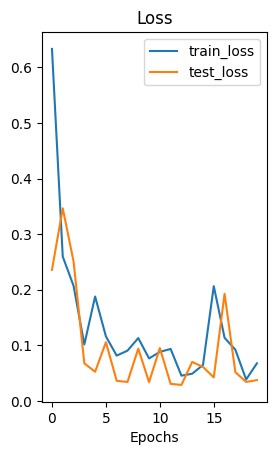

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.subplot(1,2,1)
plt.plot(np.arange(0,epochs,1), train_loss_list, label="train_loss")
plt.plot(np.arange(0,epochs,1), test_loss_list, label="test_loss")
plt.title("Loss")
plt.xlabel("Epochs")
plt.legend();

# Plot the accuracy



In [ ]:
from pathlib import Path

# 1. Create models directory
MODEL_PATH = Path("diffusion_contact_maps_v0")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# 2. Create model save path
MODEL_NAME = "ContactMapsV0.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# 3. Save the model state dict
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model_diffusion.state_dict(), f = MODEL_SAVE_PATH)

#state-dict - model's learned parameters

Saving model to: diffusion_contact_maps_v0/ContactMapsV0.pth


In [ ]:
# Loading model
import torch
from torch import nn


model_loaded = Diffusion()
# should not do things like model_diffusion(weights=None) because model_diffusion is an instance
# of the Diffusion class, doing this invokes the forward()


# Load the state dict
# loads the saved weights for the entire model.
model_loaded.load_state_dict(torch.load("diffusion_contact_maps_v0/ContactMapsV0.pth", weights_only=False))

# Set to eval mode (important for testing/inference)
model_loaded.to(device)
model_loaded.eval()

Diffusion(
  (time_embedding): TimeEmbedding(
    (linear_1): Linear(in_features=64, out_features=256, bias=True)
    (linear_2): Linear(in_features=256, out_features=256, bias=True)
  )
  (unet): UNET(
    (encoders): ModuleList(
      (0): SwitchSequential(
        (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
      (1-2): 2 x SwitchSequential(
        (0): UNET_ResidualBlock(
          (groupnorm_feature): GroupNorm(8, 64, eps=1e-05, affine=True)
          (conv_feature): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (linear_time): Linear(in_features=256, out_features=64, bias=True)
          (groupnorm_merged): GroupNorm(8, 64, eps=1e-05, affine=True)
          (conv_merged): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (residual_layer): Identity()
        )
        (1): UNET_AttentionBlock(
          (groupnorm): GroupNorm(8, 64, eps=1e-06, affine=True)
          (conv_input): Conv2d(64, 6

In [ ]:
import torch
import numpy as np
from tqdm import tqdm
# from ddpm import DDPMSampler

IMAGE_SIZE = 64
def rescale(x, old_range, new_range, clamp=True):
    old_min, old_max = old_range
    new_min, new_max = new_range
    x -= old_min
    x *= (new_max - new_min) / (old_max - old_min)
    x += new_min
    if clamp:
        x = x.clamp(new_min, new_max)
    return x

def generate(
    prompt,
    uncond_prompt=None, # Negative prompt or empty string
    # output = w * (output_conditioned-output_unconditioned) - output_unconditioned
    # weight is the cfg_scale -> indicates how much we wanna pay attention to the conditional ouput
    # wrt to the unconditional output i.e. how much attention to prompt
    # unconditional output; inference from the model twice
    # 1 with prompt, one without the prompt(which is usually an empty string), and then combined
    # tells the model how much the model shud pay attention to prompt

    input_image=None,
    strength=0.8, # if we have an input img, if we start from an img to generate another img,
    # how much attention we want to pay to an initial starting image


    do_cfg=False, # classifier free guidance
    # cfg_scale=7.5, # weight of how much the model pays attention to pay to the prompt, scale from 1 to 14
    sampler_name="ddpm",
    n_inference_steps=50,
    models={},
    seed=None,
    device=None, # where we create tensor
    idle_device=None,
    tokenizer=None,
):
    with torch.no_grad():
        if not 0 < strength <= 1:
            raise ValueError("strength must be between 0 and 1")

        if idle_device:
            to_idle = lambda x: x.to(idle_device)
        else:
            to_idle = lambda x: x

        # Initialize random number generator according to the seed specified
        generator = torch.Generator(device=device) # a random number generator
        if seed is None:
            generator.seed()
        else:
            generator.manual_seed(seed)
        if sampler_name == "ddpm":
            sampler = DDPMSampler(generator)
            sampler.set_inference_timesteps(n_inference_steps) # how many steps for inferencing
            # scheduler needs to know number of cells e..g. 50
            # during training: more steps, inference-> fewer steps, more steps = better quality bcz more noise removed
        else:
            raise ValueError(f"Unknown sampler {sampler_name}. ")

        latents_shape = (1, 1, IMAGE_SIZE,IMAGE_SIZE) # 64 x 64


        latents = torch.randn(latents_shape, generator=generator, device=device)

        # 1000, 980, 960, 940, 920...0
        # Each of these time steps indicates a noise level
        # will create a time step sched acc to what we want

        models = {"diffusion": model_loaded}
        diffusion = models["diffusion"]
        diffusion.to(device)

        timesteps = tqdm(sampler.timesteps) # unet predicts noise, scheduler removes some noise, new latent is fed to unet
        for i, timestep in enumerate(timesteps):
            # (1, 320)
            time_embedding = get_time_embedding(timestep).to(device) # use wave functions (e.g. sine, cosine) to define the timee steps

            # (Batch_Size, 1, Latents_Height, Latents_Width)
            model_input = latents

            if do_cfg: # input of variational encoder
                # (Batch_Size, 4, Latents_Height, Latents_Width) -> (2 * Batch_Size, 4, Latents_Height, Latents_Width)
                # twice the size of initial batch size
                # repeating the dimensions twice, one used with prompt, one used without the prompt
                model_input = model_input.repeat(2, 1, 1, 1) # repeating the latent twice

            context = torch.zeros((1, 77, 768), device=device)
            # model_output is the predicted noise
            # (Batch_Size, 1, Latents_Height, Latents_Width) -> (Batch_Size, 1, Latents_Height, Latents_Width)
            model_output = model_loaded(model_input, context, time_embedding).to(device)

            # after batch concatenation of cond_context & uncond_context
            # The noisy image latent $z_t$ is also duplicated so its batch size is 2: (2, 4, 64, 64).
            # The UNet processes both in a single parallel GPU operation.
            # The UNet outputs a noise tensor of shape (2, 4, 64, 64).
            # Right after the UNet forward pass, the code "splices" (splits) them back apart like this:
            if do_cfg:
                output_cond, output_uncond = model_output.chunk(2)
                model_output = cfg_scale * (output_cond - output_uncond) + output_uncond

            # remove noise predicted by the UNET
            # Loop of denoising
            # (Batch_Size, 1, Latents_Height, Latents_Width) -> (Batch_Size, 1, Latents_Height, Latents_Width)
            latents = sampler.step(timestep, latents, model_output)

        to_idle(model_loaded)

        images = rescale(latents, (-1, 1), (0, MAX_DIST_ANGSTROM), clamp=True)
        # (Batch_Size, Channel, Height, Width) -> (Batch_Size, Height, Width, Channel)
        images = images.permute(0, 2, 3, 1)
        images = images.to("cpu").float().numpy()
        return images[0]



result = generate(
    prompt=None,
    uncond_prompt=None,
    input_image=None,
    strength=0.8,
    do_cfg=False, # classifier free guidance
    # cfg_scale=7.5, # weight of how much the model pays attention to pay to the prompt, scale from 1 to 14
    sampler_name="ddpm",
    n_inference_steps=50,
    models={},
    seed=None,
    device=device, # where we create tensor
    idle_device=None,
    tokenizer=None,)
result

100%|██████████| 50/50 [02:50<00:00,  3.40s/it]


array([[[32.010468],
        [26.105927],
        [32.034115],
        ...,
        [24.645435],
        [32.69313 ],
        [32.7493  ]],

       [[33.396076],
        [28.481876],
        [27.73645 ],
        ...,
        [21.074612],
        [25.295534],
        [17.366026]],

       [[29.319824],
        [33.307415],
        [29.759098],
        ...,
        [23.196785],
        [23.13873 ],
        [33.98526 ]],

       ...,

       [[18.754225],
        [25.286293],
        [24.322372],
        ...,
        [24.858587],
        [24.608318],
        [21.014538]],

       [[16.586409],
        [22.585758],
        [24.761852],
        ...,
        [24.580118],
        [23.584904],
        [18.803934]],

       [[28.724133],
        [32.63414 ],
        [35.967983],
        ...,
        [15.488114],
        [21.851738],
        [37.758003]]], shape=(64, 64, 1), dtype=float32)

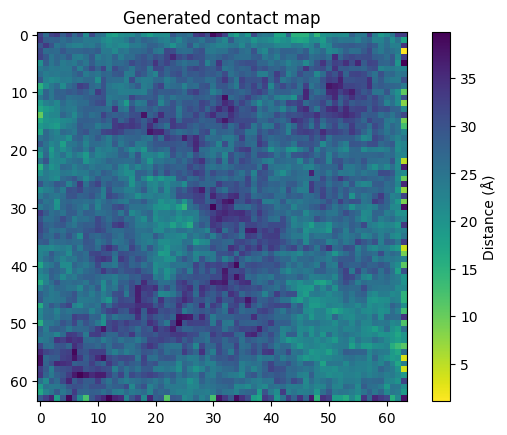

In [ ]:
import matplotlib.pyplot as plt
# generating heatmap to visualize distance matrix generated
"""
A real fold shows a bright diagonal stripe (adjacent residues are always close)
plus off-diagonal patterns -> thick parallel bands near the diagonal for helices,
or isolated bright blocks away from the diagonal for beta sheets/long-range contacts
"""
dist_matrix_angstrom = result.squeeze()
# valid_mask = map_np[:,0] != PAD_VALUE
# valid_map = map_np[valid_mask][:, valid_mask]
# dist_matrix_angstrom = ((valid_map+1)/2) * MAX_DIST_ANGSTROM

plt.imshow(dist_matrix_angstrom, cmap="viridis_r")  # reversed so close = bright
plt.colorbar(label="Distance (Å)")
plt.title("Generated contact map")
plt.show()

Mean asymmetry: 3.96 Å


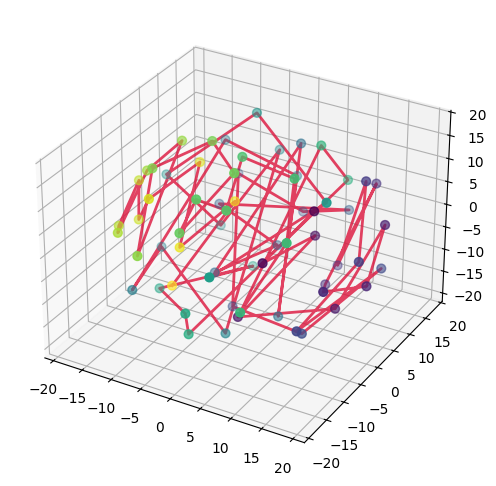

In [ ]:
from sklearn.manifold import MDS

dist_matrix_angstrom = result.squeeze()
# valid_mask = map_np[:,0] != PAD_VALUE
# valid_map = map_np[valid_mask][:, valid_mask]
# dist_matrix_angstrom = ((valid_map+1)/2) * MAX_DIST_ANGSTROM

dist_matrix_sym = (dist_matrix_angstrom + dist_matrix_angstrom.T) / 2  # force symmetry before MDS

mds = MDS(n_components=3, dissimilarity="precomputed", random_state=42, n_init=10, max_iter=500)
# max_iter = how long each attempt is allowed to optimise.
# n_init = how many independent attempts you make.

generated_coords = mds.fit_transform(dist_matrix_sym)
asymmetry = np.abs(dist_matrix_angstrom - dist_matrix_angstrom.T).mean()
print(f"Mean asymmetry: {asymmetry:.2f} Å")

# quick 3D plot to see if it looks like a plausible protein backbone shape
# Trace line connecting sequential residues
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(6,6))
ax = fig.add_subplot(projection="3d")
ax.plot(generated_coords[:, 0],
        generated_coords[:, 1],
        generated_coords[:, 2],
        color="crimson",
        linewidth=2,
        alpha=0.8,
        label = "C-alpha Trace")

# Scatter points for c-alpha atoms
ax.scatter(generated_coords[:, 0],
        generated_coords[:, 1],
        generated_coords[:, 2],
        c=np.arange(len(generated_coords)),
        cmap="viridis",
           s=40)
plt.show()

In [ ]:
gen = result          # generated map, float, shape (1, 64, 64), in [-1, 1]
d = ((train_data - gen) ** 2).flatten(1).mean(1)
print(d)                       # one value per training map
print(d.min())                 # near 0 means it's a copy

tensor([749.7667, 749.6870, 797.2340, 773.3049, 767.0088, 740.3402, 773.1520,
        771.8702])
tensor(740.3402)


TO DO LIST
1. implement the above in generation
